# Independent route certificates and release evidence

A tour is a feasible upper bound; a minimum modified-cost 1-tree supplies an exact integer lower bound. Published TSPLIB lengths are evaluation references. An exact small-instance result does not prove a larger heuristic optimal.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Recompute both large-instance lower bounds

In [2]:
from optimization_lab.routing import integer_one_tree
for name in ["berlin52","ch150"]:
    a=np.load(ROOT/f"assets/source_data/routing/{name}.npz")
    certificate=integer_one_tree(a["distance"],a["one_tree_potentials"])
    m=read(f"results/reference/routing/{name}/metrics.json")
    assert certificate["bound"]==m["one_tree_certificate"]["bound"]<=m["published_optimum"]
    print(name,certificate["bound"],m["published_optimum"])

berlin52 7542 7542
ch150 6484 6528


## Two independent exact methods

In [3]:
from optimization_lab.routing import held_karp
from optimization_lab.exact import mtz_tsp
a=np.load(ROOT/"assets/source_data/exact/tsp12.npz")
dp=held_karp(a["distance"]);milp=mtz_tsp(a["distance"])
assert dp["length"]==milp["length"]==2248 and milp["proven_optimal"]
print("Exact length",dp["length"],"MILP gap",milp["mip_gap"])

Exact length 2248 MILP gap 0.0


## Integer bound histories

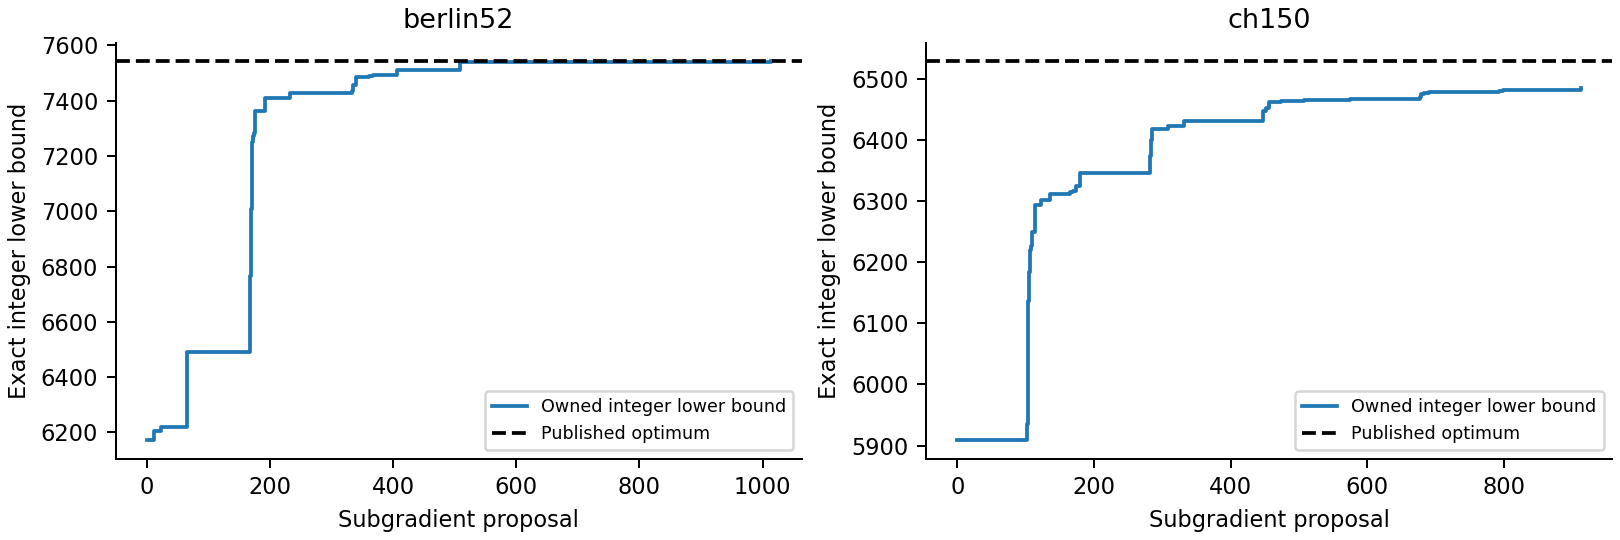

In [4]:
figure("routing_lower_bounds")

## Complete protocol counts

In [5]:
from optimization_lab.reporting import records
protocols,counts=records()
assert sum(counts.values())==31
print(counts)

{'convex': 7, 'first_order': 11, 'spectral': 1, 'geometry': 1, 'exact': 1, 'recommendation_fixed': 3, 'recommendation': 3, 'routing': 2, 'memetic': 2}


Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.